# 01. EDA данных и ограничения постановки

**Цель.** Показать, из чего состоит датасет, какие ограничения есть у логов и KPI, и почему задача раннего предупреждения не сводится к классификации отдельных строк логов.

Финальная продуктовая постановка: система видит временное окно до события и должна поднять полезный сигнал заранее, а не просто распознать факт уже наступившего сбоя.


## 1. Инициализация

**Вопрос.** Какие данные используются в финальном контуре?

**Допущение.** Старые ноутбуки остаются рабочим исследовательским контуром. Этот ноутбук строит короткую финальную витрину на уже собранном multi-rate contract и strict/intensity артефактах.


In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd()
OUT_DIR = ROOT / "outputs" / "final_notebooks"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_CONTRACT_PATH = ROOT / "outputs" / "raw_multirate" / "aligned_multirate_windows.csv"
STRICT_DIR = ROOT / "outputs" / "hades_like_v2" / "hades_v2_strict_intensity_gap10"
FINAL_ALERT_DIR = ROOT / "outputs" / "final_alert_system"

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("SEED =", SEED)
print("Выходная папка:", OUT_DIR)


SEED = 42
Выходная папка: C:\Main\DGTU\ВКР\Diploma\outputs\final_notebooks


**Локальный вывод.** Пути и seed зафиксированы, новые артефакты пишутся только в `outputs/final_notebooks/`.


## 2. Анатомия данных

**Вопрос.** Сколько run/workload доступно и насколько полно представлены модальности?


In [2]:
base_cols = pd.read_csv(RAW_CONTRACT_PATH, nrows=0).columns.tolist()
usecols = [
    col for col in [
        "run_id", "workload", "scenario", "scenario_type", "window_ts", "window_end",
        "log_available", "kpi_available", "has_both_modalities",
        "macro_log_count", "macro_error_count", "macro_warn_count",
        "y_warning", "y_risk", "event_anchor",
    ] if col in base_cols
]
raw = pd.read_csv(RAW_CONTRACT_PATH, usecols=usecols)
raw["window_ts"] = pd.to_datetime(raw["window_ts"], utc=True, errors="coerce")

strict_pred = pd.read_csv(STRICT_DIR / "ensemble_predictions.csv")
strict_pred["window_ts"] = pd.to_datetime(strict_pred["window_ts"], utc=True, errors="coerce")

summary = pd.DataFrame([
    {
        "окна": int(len(raw)),
        "run": int(raw["run_id"].nunique()),
        "workload": int(raw["workload"].nunique()),
        "доля окон с логами": float(raw.get("log_available", pd.Series(0, index=raw.index)).mean()),
        "доля окон с KPI": float(raw.get("kpi_available", pd.Series(0, index=raw.index)).mean()),
        "доля окон с обеими модальностями": float(raw.get("has_both_modalities", pd.Series(0, index=raw.index)).mean()),
        "strict test окна": int(len(strict_pred)),
        "strict test run": int(strict_pred["run_id"].nunique()),
    }
])
summary


,окна,run,workload,доля окон с логами,доля окон с KPI,доля окон с обеими модальностями,strict test окна,strict test run
0,10237,440,16,0.568135,0.999609,0.56794,795,71


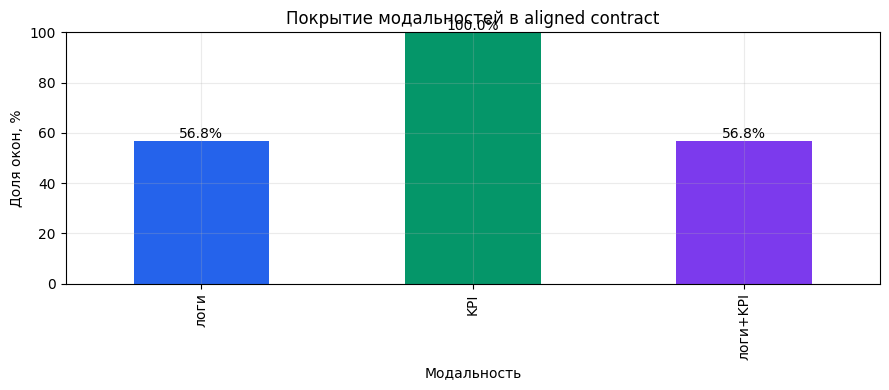

In [3]:
coverage = pd.Series({
    "логи": raw.get("log_available", pd.Series(0, index=raw.index)).mean(),
    "KPI": raw.get("kpi_available", pd.Series(0, index=raw.index)).mean(),
    "логи+KPI": raw.get("has_both_modalities", pd.Series(0, index=raw.index)).mean(),
}).mul(100)

ax = coverage.plot(kind="bar", color=["#2563eb", "#059669", "#7c3aed"])
ax.set_title("Покрытие модальностей в aligned contract")
ax.set_ylabel("Доля окон, %")
ax.set_xlabel("Модальность")
ax.set_ylim(0, 100)
for i, value in enumerate(coverage):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")
plt.tight_layout()
plt.show()


**Что показано.** Масштаб contract и покрытие модальностей.

**Что наблюдается.** На уровне окон логи и KPI доступны не всегда одновременно.

**Локальный вывод.** Финальная модель должна получать маски доступности модальностей, иначе fusion будет скрыто подменяться fallback-логикой.


## 3. Lead time и неоднородность времени

**Вопрос.** Почему `gap10` и intensity важнее простой бинарной метки?


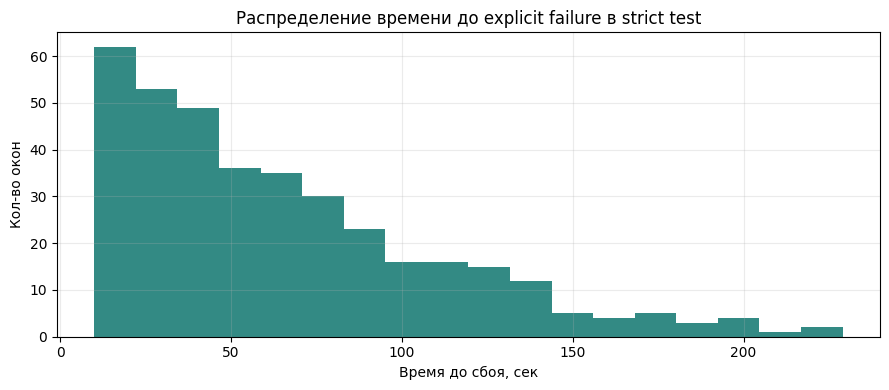

,strict_lead_sec
count,371.000000
mean,65.199461
std,45.646445
min,10.000000
10%,18.000000
25%,30.000000
50%,52.000000
75%,89.000000
90%,131.000000
max,229.000000


In [4]:
lead = pd.to_numeric(strict_pred.get("strict_lead_sec", np.nan), errors="coerce").dropna()
fig, ax = plt.subplots()
ax.hist(lead, bins=18, color="#0f766e", alpha=0.85)
ax.set_title("Распределение времени до explicit failure в strict test")
ax.set_xlabel("Время до сбоя, сек")
ax.set_ylabel("Кол-во окон")
plt.tight_layout()
plt.show()

lead.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_frame("strict_lead_sec")


**Что показано.** Распределение расстояния от окна наблюдения до explicit failure.

**Что наблюдается.** Окно за 120 сек и окно за 10 сек имеют разный продуктовый смысл. Жесткая бинарная метка эту структуру теряет.

**Локальный вывод.** В финальной модели используется intensity score: он учит не только класс окна, но и нарастание риска к событию.


## 4. Дисбаланс и риск утечки

**Вопрос.** Почему сильный log-only baseline не равен хорошей early-alert системе?


In [5]:
class_balance = pd.DataFrame([
    {"метрика": "окна", "значение": int(len(strict_pred))},
    {"метрика": "warning positives", "значение": int(strict_pred["y_warning"].sum())},
    {"метрика": "risk positives", "значение": int(strict_pred["y_risk"].sum())},
    {"метрика": "warning prevalence", "значение": float(strict_pred["y_warning"].mean())},
    {"метрика": "risk prevalence", "значение": float(strict_pred["y_risk"].mean())},
])
class_balance


,метрика,значение
0,окна,795.000000
1,warning positives,321.000000
2,risk positives,94.000000
3,warning prevalence,0.403774
4,risk prevalence,0.118239


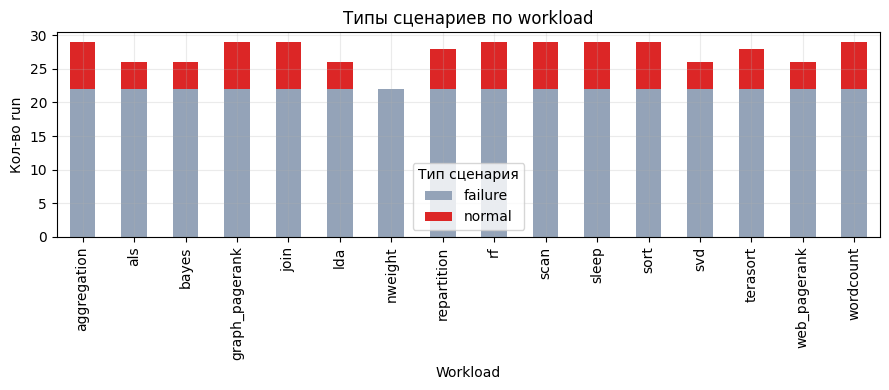

In [6]:
scenario_runs = raw.drop_duplicates("run_id").groupby(["scenario_type", "workload"]).size().unstack(fill_value=0)
ax = scenario_runs.T.plot(kind="bar", stacked=True, color=["#94a3b8", "#dc2626", "#f59e0b"])
ax.set_title("Типы сценариев по workload")
ax.set_ylabel("Кол-во run")
ax.set_xlabel("Workload")
ax.legend(title="Тип сценария")
plt.tight_layout()
plt.show()


**Что показано.** Дисбаланс strict/test окон и распределение сценариев.

**Что наблюдается.** `risk` редкий. Кроме того, поздние логи могут содержать уже наступившие симптомы (`error`, `killed`, `failed`), что делает log-only baseline сильным, но не всегда ранним.

**Локальный вывод.** Следующий этап должен зафиксировать strict contract, gap до события, split без смешивания run/workload и честные baseline.


## 5. Handoff в 02

В следующий ноутбук передается требование:

- использовать окна наблюдения, а не строки логов;
- фиксировать `strict_lead_sec` и `gap10`;
- проверять split по run/workload;
- считать log-only, KPI-only, availability-only и простой fused baseline;
- не использовать target/proxy как dashboard score.


In [7]:
eda_summary = {
    "seed": SEED,
    "raw_contract_path": str(RAW_CONTRACT_PATH.relative_to(ROOT)),
    "strict_prediction_path": str((STRICT_DIR / "ensemble_predictions.csv").relative_to(ROOT)),
    "rows": int(len(raw)),
    "runs": int(raw["run_id"].nunique()),
    "workloads": int(raw["workload"].nunique()),
    "log_window_coverage": float(raw.get("log_available", pd.Series(0, index=raw.index)).mean()),
    "kpi_window_coverage": float(raw.get("kpi_available", pd.Series(0, index=raw.index)).mean()),
    "both_modalities_coverage": float(raw.get("has_both_modalities", pd.Series(0, index=raw.index)).mean()),
    "strict_test_rows": int(len(strict_pred)),
    "strict_test_runs": int(strict_pred["run_id"].nunique()),
}
path = OUT_DIR / "01_eda_summary.json"
path.write_text(json.dumps(eda_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Записан артефакт:", path.relative_to(ROOT))


Записан артефакт: outputs\final_notebooks\01_eda_summary.json


**Итоговый вывод.** Данные мультимодальные, неоднородные и дисбалансные; поэтому финальная защита строится вокруг early-alert pipeline, а не вокруг точности бинарной классификации окон.
